In [1]:
# %% Cell 1 — Instalasi pustaka
!pip -q install ucimlrepo

In [2]:
# %% Cell 2 — Import pustaka
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Semua pustaka berhasil diimpor.")


Semua pustaka berhasil diimpor.


In [3]:
# %% Cell 3 — Mengambil dataset asli dari UCI
dataset = fetch_ucirepo(id=374)

X_asli = dataset.data.features.copy()
y_asli = dataset.data.targets.copy()

df_asli = pd.concat([X_asli, y_asli], axis=1)

print("Ukuran fitur:", X_asli.shape)
print("Ukuran target:", y_asli.shape)
print("Ukuran dataset gabungan:", df_asli.shape)

display(df_asli.head())


Ukuran fitur: (19735, 28)
Ukuran target: (19735, 1)
Ukuran dataset gabungan: (19735, 29)


,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances
0,2016-01-1117:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,60
1,2016-01-1117:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,60
2,2016-01-1117:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,50
3,2016-01-1117:30:00,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390,50
4,2016-01-1117:40:00,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,60


In [4]:
# %% Cell 4 — Memeriksa struktur dataset
print("Nama kolom:")
print(df_asli.columns.tolist())

print("\nInformasi dataset:")
df_asli.info()

print("\nJumlah baris dan kolom:")
print(df_asli.shape)

print("\nJumlah data kosong per kolom:")
display(df_asli.isna().sum().to_frame("Jumlah kosong"))


Nama kolom:
['date', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'Appliances']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   lights       19735 non-null  int64  
 2   T1           19735 non-null  float64
 3   RH_1         19735 non-null  float64
 4   T2           19735 non-null  float64
 5   RH_2         19735 non-null  float64
 6   T3           19735 non-null  float64
 7   RH_3         19735 non-null  float64
 8   T4           19735 non-null  float64
 9   RH_4         19735 non-null  float64
 10  T5           19735 non-null  float64
 11  RH_5         19735 non-null  float64
 12  T6           19735 

,Jumlah kosong
date,0
lights,0
T1,0
RH_1,0
T2,0
RH_2,0
T3,0
RH_3,0
T4,0
RH_4,0


In [7]:

# %% Cell 5 — Membersihkan dataset dan memperbaiki format tanggal

# Mengambil ulang data dari Cell 3
df_bersih = df_asli.copy()

# Memperbaiki tanggal yang menempel dengan jam
# Contoh: 2016-01-1117:00:00 menjadi 2016-01-11 17:00:00
df_bersih["date"] = (
    df_bersih["date"]
    .astype(str)
    .str.replace(
        r"^(\d{4}-\d{2}-\d{2})(\d{2}:\d{2}:\d{2})$",
        r"\1 \2",
        regex=True
    )
)

# Mengubah tanggal menjadi datetime
df_bersih["date"] = pd.to_datetime(
    df_bersih["date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Memastikan target berupa angka
df_bersih["Appliances"] = pd.to_numeric(
    df_bersih["Appliances"],
    errors="coerce"
)

print("Contoh tanggal setelah diperbaiki:")
display(df_bersih[["date", "Appliances"]].head())

print("\nJumlah tanggal valid:", df_bersih["date"].notna().sum())
print("Jumlah target energi valid:", df_bersih["Appliances"].notna().sum())

# Menghapus baris yang tanggal atau targetnya tidak valid
jumlah_awal = len(df_bersih)

df_bersih = df_bersih.dropna(
    subset=["date", "Appliances"]
).copy()

print("\nJumlah baris sebelum pembersihan:", jumlah_awal)
print("Jumlah baris setelah pembersihan:", len(df_bersih))
print("Ukuran data bersih:", df_bersih.shape)

assert not df_bersih.empty, (
    "Data masih kosong. Periksa format tanggal kembali."
)


Contoh tanggal setelah diperbaiki:


,date,Appliances
0,2016-01-11 17:00:00,60
1,2016-01-11 17:10:00,60
2,2016-01-11 17:20:00,50
3,2016-01-11 17:30:00,50
4,2016-01-11 17:40:00,60



Jumlah tanggal valid: 19735
Jumlah target energi valid: 19735

Jumlah baris sebelum pembersihan: 19735
Jumlah baris setelah pembersihan: 19735
Ukuran data bersih: (19735, 29)


In [8]:
# %% Cell 6 — Membuat variabel waktu
df_bersih["jam"] = df_bersih["date"].dt.hour
df_bersih["hari_dalam_minggu"] = df_bersih["date"].dt.dayofweek
df_bersih["bulan"] = df_bersih["date"].dt.month

nama_hari = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

df_bersih["nama_hari"] = (
    df_bersih["hari_dalam_minggu"].map(nama_hari)
)

display(
    df_bersih[
        ["date", "jam", "nama_hari", "bulan", "Appliances"]
    ].head()
)

print("Jumlah data:", len(df_bersih))


,date,jam,nama_hari,bulan,Appliances
0,2016-01-11 17:00:00,17,Senin,1,60
1,2016-01-11 17:10:00,17,Senin,1,60
2,2016-01-11 17:20:00,17,Senin,1,50
3,2016-01-11 17:30:00,17,Senin,1,50
4,2016-01-11 17:40:00,17,Senin,1,60


Jumlah data: 19735


In [9]:
# %% Cell 7 — Statistik deskriptif
print("Jumlah data:", len(df_bersih))
print("Periode awal:", df_bersih["date"].min())
print("Periode akhir:", df_bersih["date"].max())

print("\nStatistik konsumsi energi:")
display(df_bersih["Appliances"].describe().to_frame())

print(
    "\nRata-rata konsumsi energi:",
    round(df_bersih["Appliances"].mean(), 2),
    "Wh per interval"
)


Jumlah data: 19735
Periode awal: 2016-01-11 17:00:00
Periode akhir: 2016-05-27 18:00:00

Statistik konsumsi energi:


,Appliances
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000



Rata-rata konsumsi energi: 97.69 Wh per interval


,Rata-rata energi (Wh)
date,
0,52.785888
1,51.326034
2,49.075426
3,48.236010
4,49.355231
5,52.737226
6,57.712895
7,78.649635
8,106.143552


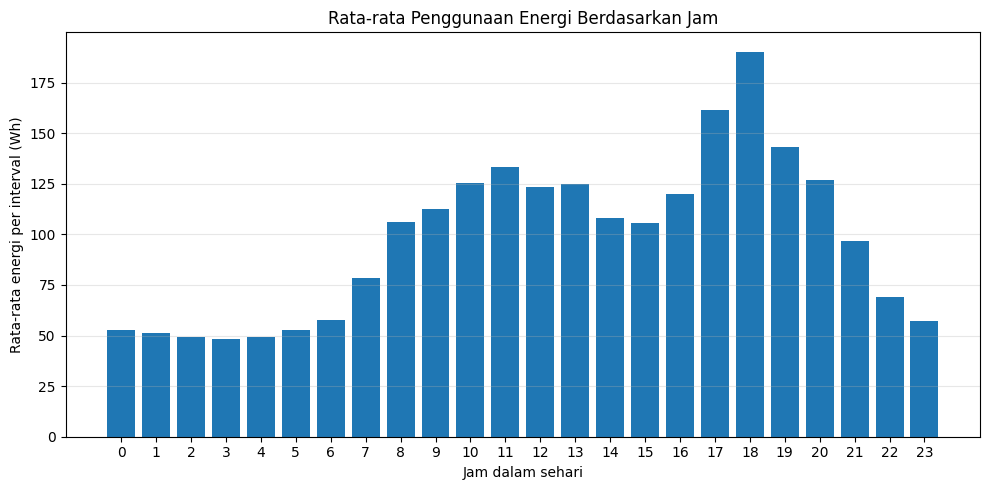

Jam dengan rata-rata konsumsi energi tertinggi: 18:00


In [10]:
# %% Cell 8 — Grafik konsumsi energi berdasarkan jam
rata_per_jam = (
    df_bersih.groupby(df_bersih["date"].dt.hour)["Appliances"]
    .mean()
    .reindex(range(24))
)

display(
    rata_per_jam.rename(
        "Rata-rata energi (Wh)"
    ).to_frame()
)

plt.figure(figsize=(10, 5))
plt.bar(rata_per_jam.index, rata_per_jam.values)
plt.title("Rata-rata Penggunaan Energi Berdasarkan Jam")
plt.xlabel("Jam dalam sehari")
plt.ylabel("Rata-rata energi per interval (Wh)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

jam_tertinggi = int(rata_per_jam.idxmax())
print(
    f"Jam dengan rata-rata konsumsi energi tertinggi: "
    f"{jam_tertinggi:02d}:00"
)


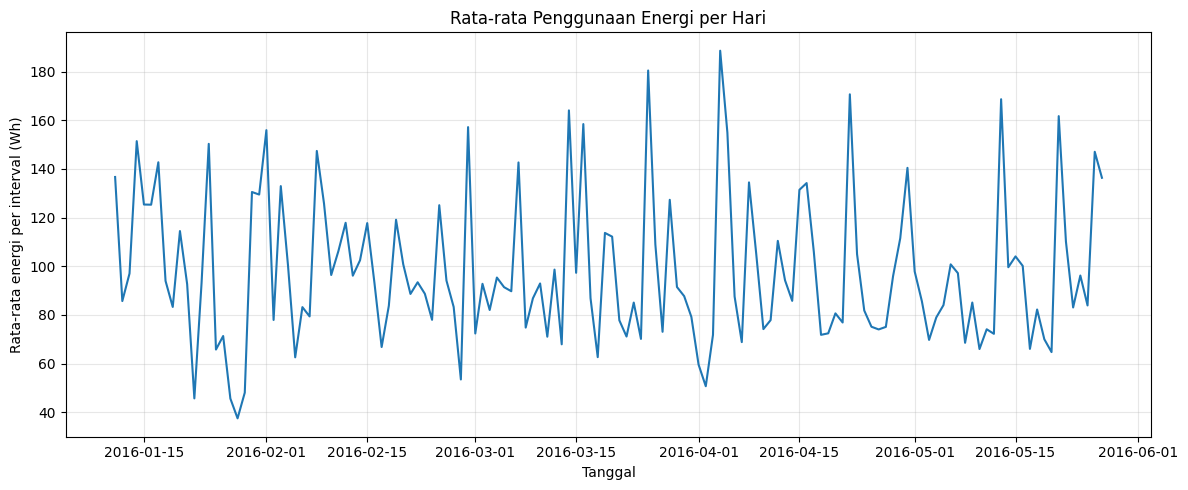

In [11]:
# %% Cell 9 — Grafik konsumsi energi harian
rata_harian = (
    df_bersih.set_index("date")["Appliances"]
    .resample("D")
    .mean()
    .dropna()
)

plt.figure(figsize=(12, 5))
plt.plot(rata_harian.index, rata_harian.values)
plt.title("Rata-rata Penggunaan Energi per Hari")
plt.xlabel("Tanggal")
plt.ylabel("Rata-rata energi per interval (Wh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
# %% Cell 10 — Menyiapkan fitur dan target
df_model = df_bersih.copy()

# Fitur waktu
df_model["jam"] = df_model["date"].dt.hour
df_model["hari_dalam_minggu"] = df_model["date"].dt.dayofweek
df_model["bulan"] = df_model["date"].dt.month

# Menghapus kolom yang tidak digunakan sebagai fitur
kolom_hapus = [
    "date",
    "Appliances",
    "rv1",
    "rv2",
    "nama_hari"
]

X = df_model.drop(
    columns=kolom_hapus,
    errors="ignore"
)

y = df_model["Appliances"]

# Pastikan seluruh fitur berupa numerik
X = X.apply(pd.to_numeric, errors="coerce")

# Mengganti nilai tak hingga dengan NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Isi nilai kosong menggunakan median dari data yang tersedia
X = X.fillna(X.median()).fillna(0)

print("Ukuran fitur X:", X.shape)
print("Ukuran target y:", y.shape)
print("Apakah X masih memiliki nilai kosong?", X.isna().any().any())

display(X.head())


Ukuran fitur X: (19735, 28)
Ukuran target y: (19735,)
Apakah X masih memiliki nilai kosong? False


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,jam,hari_dalam_minggu,bulan
0,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,...,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,17,0,1
1,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,...,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,17,0,1
2,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,...,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,17,0,1
3,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,...,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,17,0,1
4,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,...,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,17,0,1


In [13]:
# %% Cell 11 — Membagi data secara kronologis
urutan_waktu = np.argsort(
    df_model["date"].to_numpy()
)

X_urut = X.iloc[urutan_waktu].reset_index(drop=True)
y_urut = y.iloc[urutan_waktu].reset_index(drop=True)

batas = int(len(X_urut) * 0.8)

X_train = X_urut.iloc[:batas]
X_test = X_urut.iloc[batas:]

y_train = y_urut.iloc[:batas]
y_test = y_urut.iloc[batas:]

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))
print("Total data:", len(X_train) + len(X_test))


Jumlah data latih: 15788
Jumlah data uji: 3947
Total data: 19735


In [14]:
# %% Cell 12 — Membuat model baseline
model_baseline = DummyRegressor(strategy="mean")

model_baseline.fit(X_train, y_train)

prediksi_baseline = model_baseline.predict(X_test)

print("Model baseline berhasil dilatih.")


Model baseline berhasil dilatih.


In [15]:
# %% Cell 13 — Melatih model Random Forest
model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

prediksi_rf = model_rf.predict(X_test)

print("Model Random Forest berhasil dilatih.")


Model Random Forest berhasil dilatih.


In [16]:
# %% Cell 14 — Evaluasi model
def hitung_metrik(nama, aktual, prediksi):
    return {
        "Model": nama,
        "MAE": mean_absolute_error(aktual, prediksi),
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "R2": r2_score(aktual, prediksi)
    }

hasil_evaluasi = pd.DataFrame([
    hitung_metrik(
        "Baseline", y_test, prediksi_baseline
    ),
    hitung_metrik(
        "Random Forest", y_test, prediksi_rf
    )
])

display(hasil_evaluasi.round(4))


,Model,MAE,RMSE,R2
0,Baseline,52.6849,91.0534,-0.0003
1,Random Forest,170.3820,209.7498,-4.3083


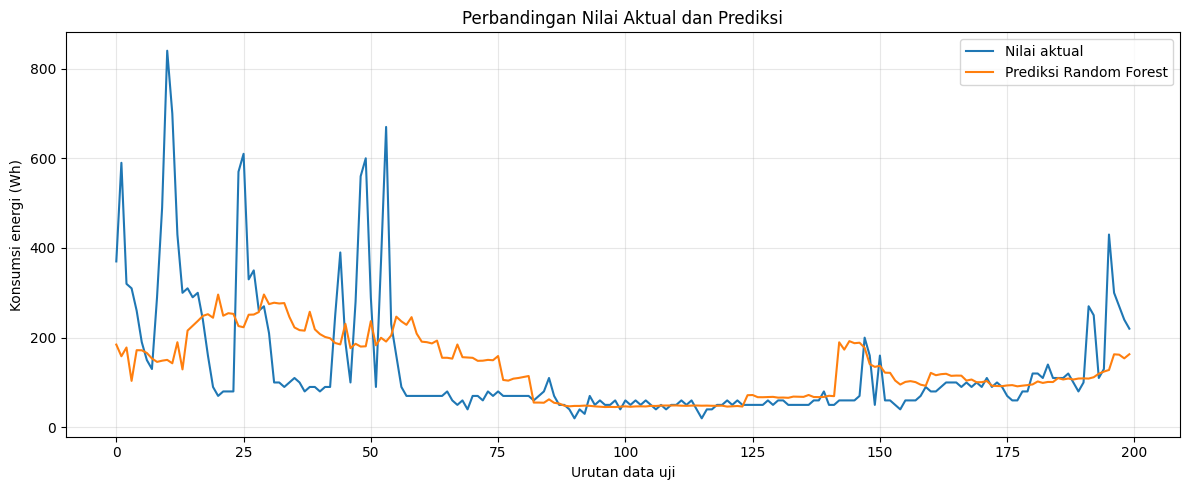

In [17]:
# %% Cell 15 — Grafik nilai aktual dan prediksi
jumlah_tampil = min(200, len(y_test))

plt.figure(figsize=(12, 5))

plt.plot(
    range(jumlah_tampil),
    y_test.iloc[:jumlah_tampil].to_numpy(),
    label="Nilai aktual"
)

plt.plot(
    range(jumlah_tampil),
    prediksi_rf[:jumlah_tampil],
    label="Prediksi Random Forest"
)

plt.title("Perbandingan Nilai Aktual dan Prediksi")
plt.xlabel("Urutan data uji")
plt.ylabel("Konsumsi energi (Wh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Fitur,Kepentingan
25,jam,0.157426
5,T3,0.064506
6,RH_3,0.048826
20,Press_mm_hg,0.044519
10,RH_5,0.043066
15,T8,0.042014
4,RH_2,0.039683
8,RH_4,0.034731
0,lights,0.032259
24,Tdewpoint,0.032037


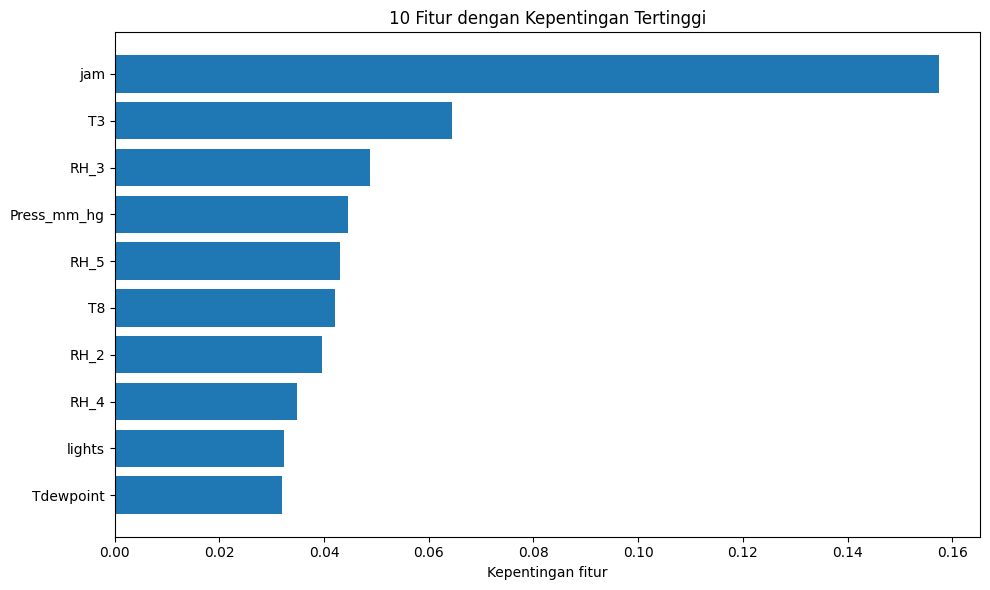

In [18]:
# %% Cell 16 — Analisis kepentingan fitur
kepentingan = pd.DataFrame({
    "Fitur": X_train.columns,
    "Kepentingan": model_rf.feature_importances_
}).sort_values(
    "Kepentingan",
    ascending=False
)

display(kepentingan.head(10))

data_plot = kepentingan.head(10).sort_values(
    "Kepentingan"
)

plt.figure(figsize=(10, 6))
plt.barh(
    data_plot["Fitur"],
    data_plot["Kepentingan"]
)

plt.title("10 Fitur dengan Kepentingan Tertinggi")
plt.xlabel("Kepentingan fitur")
plt.tight_layout()
plt.show()


In [19]:
# %% Cell 17 — Menyimpan hasil analisis
os.makedirs("hasil_proyek", exist_ok=True)

# Menyimpan hasil prediksi
hasil_prediksi = pd.DataFrame({
    "Aktual_Wh": y_test.reset_index(drop=True),
    "Prediksi_Wh": prediksi_rf
})

hasil_prediksi.to_csv(
    "hasil_proyek/hasil_prediksi.csv",
    index=False
)

# Menyimpan hasil evaluasi
hasil_evaluasi.to_csv(
    "hasil_proyek/hasil_evaluasi.csv",
    index=False
)

# Menyimpan kepentingan fitur
kepentingan.to_csv(
    "hasil_proyek/kepentingan_fitur.csv",
    index=False
)

# Menyimpan data ringkasan per jam
rata_per_jam.rename(
    "Rata-rata energi (Wh)"
).to_csv("hasil_proyek/rata_rata_per_jam.csv")

print("Hasil berhasil disimpan:")
print(os.listdir("hasil_proyek"))


Hasil berhasil disimpan:
['kepentingan_fitur.csv', 'rata_rata_per_jam.csv', 'hasil_prediksi.csv', 'hasil_evaluasi.csv']


In [20]:
# %% Cell 18 — Membuat ringkasan hasil analisis
baris_rf = hasil_evaluasi.loc[
    hasil_evaluasi["Model"] == "Random Forest"
].iloc[0]

baris_baseline = hasil_evaluasi.loc[
    hasil_evaluasi["Model"] == "Baseline"
].iloc[0]

fitur_teratas = kepentingan.iloc[0]["Fitur"]

ringkasan = f"""
RINGKASAN HASIL PROYEK

Jumlah data: {len(df_bersih)}
Jumlah fitur model: {X.shape[1]}
Jumlah data latih: {len(X_train)}
Jumlah data uji: {len(X_test)}

Hasil Random Forest:
MAE  = {baris_rf['MAE']:.4f}
RMSE = {baris_rf['RMSE']:.4f}
R2   = {baris_rf['R2']:.4f}

Hasil baseline:
MAE  = {baris_baseline['MAE']:.4f}
RMSE = {baris_baseline['RMSE']:.4f}
R2   = {baris_baseline['R2']:.4f}

Fitur dengan kepentingan tertinggi:
{fitur_teratas}

Catatan:
Hasil evaluasi berlaku untuk pembagian data dan konfigurasi
model pada proyek ini. Kepentingan fitur bukan bukti sebab-akibat.
"""

print(ringkasan)

with open(
    "hasil_proyek/ringkasan_hasil.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(ringkasan)



RINGKASAN HASIL PROYEK

Jumlah data: 19735
Jumlah fitur model: 28
Jumlah data latih: 15788
Jumlah data uji: 3947

Hasil Random Forest:
MAE  = 170.3820
RMSE = 209.7498
R2   = -4.3083

Hasil baseline:
MAE  = 52.6849
RMSE = 91.0534
R2   = -0.0003

Fitur dengan kepentingan tertinggi:
jam

Catatan:
Hasil evaluasi berlaku untuk pembagian data dan konfigurasi
model pada proyek ini. Kepentingan fitur bukan bukti sebab-akibat.



In [21]:
# %% Cell 19 — Membuat ZIP hasil analisis
import shutil

shutil.make_archive(
    "hasil_proyek",
    "zip",
    root_dir="hasil_proyek"
)

print("File hasil_proyek.zip berhasil dibuat.")


File hasil_proyek.zip berhasil dibuat.


In [22]:
# %% Cell 20 — Mengunduh ZIP
from google.colab import files

files.download("hasil_proyek.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>